# Risk inference timing


# Experiment: Average Risk Compute Time

Measures the wall-clock cost of a single risk evaluation (`DynamicRisk.compute_risk`),
which bundles discretization/evidence-setting, BBN inference and cost-model
computation into one call.

## Setup and Validate

create the obstacles and load the map.

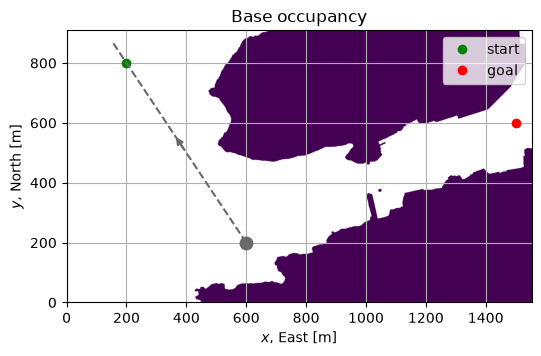

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cartoblobpy.graph import Graph

from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *

g = Graph()
g.load_from_yaml("../maps/kristiansund_bridge/map.yaml")
g.start = (200.0, 800.0)
g.goal = (1500, 600.0)
obstacles = [
    LinearDynamicObstacle.create(
        start_pose=(600.0, 200.0), end_pose=(200.0, 800.0), velocity=2.0
    ),
]

fig, ax = plt.subplots(figsize=(6, 6))


g.plot(ax=ax)
plot_obstacles(obstacles, ax=ax, max_time=400.0)
plt.grid(True)

## Create the experiment matrix

In [2]:
import itertools

alpha_values = [0.1]
beta_values = [100.0]
gamma_values = [0.6]
max_nodes = [750, 1000, 1250, 1500, 1750, 2000, 2250, 2500]
number_of_runs_per_configuration = 5

# create a list of all configurations to test
keys = [
    "ALPHA",
    "BETA",
    "GAMMA",
    "MAX_NODES",
    "RUN_ID",
]

experiment_matrix = [
    dict(zip(keys, values))
    for values in itertools.product(
        alpha_values,
        beta_values,
        gamma_values,
        max_nodes,
        range(number_of_runs_per_configuration),
    )
]

len(experiment_matrix), experiment_matrix[:2]

(40,
 [{'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 0},
  {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 1}])

In [3]:
# Wall-clock time [s] per risk evaluation, pooled across runs, keyed by MAX_NODES.
risk_compute_times_by_max_nodes = {n: [] for n in max_nodes}

# Number of BBN calls (risk evaluations) in a single run, one entry per run,
# keyed by MAX_NODES. This is ncalls_tot for that configuration.
ncalls_by_max_nodes = {n: [] for n in max_nodes}

## Run the experiments and collect results

In [ ]:
import time

from risk_informed_planner.config import Config
from risk_informed_planner.risk.cost_model import *
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch,
    progress_bar,
)
from risk_informed_planner.utils import Node
from risk_informed_planner.risk import cost_model

for idx, exp in enumerate(experiment_matrix):
    print(f"Running configuration ({idx + 1}/{len(experiment_matrix)}): {exp}")

    start = Node(g.start[0], g.start[1], 0)
    goal = Node(g.goal[0], g.goal[1], -1)

    cfg = Config(
        X_LIMITS=(0, g.width),
        Y_LIMITS=(0, g.height),
        STEP_SIZE=50,
        GOAL_RADIUS=75,
        NEIGHBOR_RADIUS=150,
        MAX_NODES=exp["MAX_NODES"],
        ALPHA=exp["ALPHA"],
        BETA=exp["BETA"],
        GAMMA=exp["GAMMA"],
        RISK_CUTOFF=np.inf,
        MAX_TURN_ANGLE=np.pi / 4,
        RISK_SAMPLE_SPACING=30.0,
        RISK_AGGREGATION="max",
    )

    min_depth = 10.0
    risk_model = DynamicRisk(
        max_distance_from_shore=150.0,
        lookahead_distance=150.0,
        graph=g,
        obstacles=obstacles,
        max_dcpa_for_collision_risk=50.0,
        max_tcpa_for_collision_risk=120.0,
        max_relative_velocity_for_collision_risk=5.0,
        grounding_depth_hard_limit=min_depth,
        desired_speed=3.0,
        cost_model=cost_model.NormalizedExpectedLoss(),
    )

    free_check_method = RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.OCCUPANCY

    path_planner = RiskAwareAngleCostRRTStarSearch(
        start=start,
        goal=goal,
        graph=g,
        cfg=cfg,
        risk_model=risk_model,
        record_bbn_snapshots=False,
        min_depth=min_depth,
        free_check_method=free_check_method,
        callback_functions=[progress_bar],
    )

    start_time = time.perf_counter()
    nodes, path = path_planner()
    total_computation_time = time.perf_counter() - start_time
    print(
        f"Planning completed in {total_computation_time:.2f} seconds "
        f"({path_planner.risk_evaluations} risk evaluations)."
    )
    print("\n")

    risk_compute_times_by_max_nodes[exp["MAX_NODES"]].extend(path_planner.risk_compute_times)
    ncalls_by_max_nodes[exp["MAX_NODES"]].append(path_planner.risk_evaluations)


# save stats to a file with numpy utilities. Dicts round-trip fine through
# np.savez as pickled 0-d object arrays; load back with allow_pickle=True and
# `.item()`.

np.savez(
    "experiment_compute_average_risk_compute_time_stats.npz",
    alpha_values=alpha_values,
    beta_values=beta_values,
    gamma_values=gamma_values,
    max_nodes=max_nodes,
    number_of_runs_per_configuration=number_of_runs_per_configuration,
    risk_compute_times_by_max_nodes=risk_compute_times_by_max_nodes,
    ncalls_by_max_nodes=ncalls_by_max_nodes,
)


Running configuration (1/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 0}


Progress:   0%|          | 0/750 [00:00<?, ?node/s]

Planning completed in 6.26 seconds (35033 risk evaluations).


Running configuration (2/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 1}


Progress:   0%|          | 0/750 [00:00<?, ?node/s]

Planning completed in 6.19 seconds (33475 risk evaluations).


Running configuration (3/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 750, 'RUN_ID': 2}


Progress:   0%|          | 0/750 [00:00<?, ?node/s]

... (8 outputs left out)

Planning completed in 9.55 seconds (58196 risk evaluations).


Running configuration (8/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 1000, 'RUN_ID': 2}


Progress:   0%|          | 0/1000 [00:00<?, ?node/s]

Planning completed in 10.75 seconds (61331 risk evaluations).


Running configuration (9/40): {'ALPHA': 0.1, 'BETA': 100.0, 'GAMMA': 0.6, 'MAX_NODES': 1000, 'RUN_ID': 3}


Progress:   0%|          | 0/1000 [00:00<?, ?node/s]

In [ ]:
data = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
risk_compute_times_by_max_nodes = data["risk_compute_times_by_max_nodes"].item()

nodes_sorted = sorted(risk_compute_times_by_max_nodes)
pooled_ms = np.concatenate([np.array(risk_compute_times_by_max_nodes[n]) * 1e3 for n in nodes_sorted])

mean_ms = float(pooled_ms.mean())
std_ms = float(pooled_ms.std())
median_ms = float(np.median(pooled_ms))

print(f"Risk evaluations pooled (all MAX_NODES) : {pooled_ms.size}")
print(f"Average compute time                    : {mean_ms:.4f} ms  (discretization + BBN inference + cost computation)")
print(f"Std. deviation                          : {std_ms:.4f} ms")
print(f"Median                                   : {median_ms:.4f} ms")
print(f"Min / Max                                : {pooled_ms.min():.4f} / {pooled_ms.max():.4f} ms")


"""Paper-style boxplot: per-call risk compute time vs. MAX_NODES.

Sanity check -- a single risk evaluation shouldn't depend on how many nodes
are already in the tree, so this should be flat.
"""

import matplotlib.pyplot as plt

INK = "#1f3b4d"
MEDIAN = "#2ca02c"

enable_latex(True)

data_per_n = [np.array(risk_compute_times_by_max_nodes[n]) * 1e3 for n in nodes_sorted]
pos = np.arange(len(nodes_sorted))

fig, ax = plt.subplots(figsize=(5.0, 3.0))

ax.boxplot(
    data_per_n,
    positions=pos,
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    zorder=3,
    boxprops=dict(facecolor="white", edgecolor=INK, linewidth=0.9),
    medianprops=dict(color=MEDIAN, linewidth=1.6),
    whiskerprops=dict(color=INK, linewidth=0.9),
    capprops=dict(color=INK, linewidth=0.9),
)

ax.set_xticks(pos)
ax.set_xticklabels(nodes_sorted)
ax.set_xlabel("Maximum number of nodes")
ax.set_ylabel("Risk compute time per call [ms]")

ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
ax.xaxis.grid(False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_color("black")

fig.tight_layout()
fig.savefig("risk_compute_time_per_call_vs_nodes.png", bbox_inches="tight")
fig.savefig("risk_compute_time_per_call_vs_nodes.pdf", bbox_inches="tight")
plt.show()


## Real-time budget vs. MAX_NODES

Fills in the two blanks of the "Real-time requirements" subsection, this time
as a function of $\maxnodes$ rather than at a single point.

* **measured** $\tinf$ -- the mean of `risk_compute_times_by_max_nodes[n]`,
  should be roughly flat in $n$: one BBN evaluation doesn't get more
  expensive because the tree has more nodes in it.
* **budget** $\tinf(n)$ -- Eq.~(budget), evaluated at $\maxnodes = n$.

As before, rather than guessing $\nfeas$ and $\bar{\nsamp}$ separately, the
budget collapses (via the identity in Eq.~(total)) to

$$
  \tinf \;\le\; \deadline \,/\, \ncalls_{\mathrm{tot}}(n) ,
$$

using the *measured* $\ncalls_{\mathrm{tot}}(n)$ (mean risk-evaluation count
per run) at each $n$. Because $\ncalls_{\mathrm{tot}}(n)$ grows
quadratically (Eq.~(total)) while measured $\tinf$ stays flat, the budget
curve falls while the measured curve doesn't -- the two cross at some
$\maxnodes$, past which the network can no longer keep up with the
scenario's deadline.

In [ ]:
import operator

data = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
risk_compute_times_by_max_nodes = data["risk_compute_times_by_max_nodes"].item()
ncalls_by_max_nodes = data["ncalls_by_max_nodes"].item()
nodes_sorted = sorted(risk_compute_times_by_max_nodes)

# --- deadline: Eq. (deadline), from the scenario settings used above ---
tcpa_s = risk_model.max_tcpa_for_collision_risk
lookahead_over_speed_s = risk_model.lookahead_distance / risk_model.desired_speed
deadline_s = min(tcpa_s, lookahead_over_speed_s)

# --- geometry: nbrad, A (both independent of MAX_NODES) ---
nbrad_m = cfg.NEIGHBOR_RADIUS
free_mask = g.free_space_mask(threshold=0.5, op=operator.le)
A_m2 = free_mask.sum() * (g.resolution ** 2)

rows = []
for n in nodes_sorted:
    ncalls_tot = float(np.mean(ncalls_by_max_nodes[n]))
    measured_ms = float(np.mean(risk_compute_times_by_max_nodes[n]) * 1e3)
    budget_ms = (deadline_s * 1e3) / ncalls_tot
    nfeas_nsamp_bar = (ncalls_tot * A_m2) / (np.pi * nbrad_m**2 * n**2)
    rows.append(
        dict(
            max_nodes=n,
            ncalls_tot=ncalls_tot,
            measured_ms=measured_ms,
            budget_ms=budget_ms,
            exceeds_by=measured_ms / budget_ms,
            nfeas_nsamp_bar=nfeas_nsamp_bar,
        )
    )

print(f"deadline = min(tcpa={tcpa_s:.0f}s, lookahead/speed={lookahead_over_speed_s:.0f}s) = {deadline_s:.0f} s")
print(f"nbrad = {nbrad_m:.0f} m, A = {A_m2:,.0f} m^2")
print()
header = f"{'MAX_NODES':>9} | {'ncalls_tot':>11} | {'measured [ms]':>13} | {'budget [ms]':>11} | {'exceeds by':>10}"
print(header)
print("-" * len(header))
for r in rows:
    print(
        f"{r['max_nodes']:>9} | {r['ncalls_tot']:>11,.0f} | {r['measured_ms']:>13.4f} | "
        f"{r['budget_ms']:>11.4f} | {r['exceeds_by']:>9.2f}x"
    )

crossing = next((r["max_nodes"] for r in rows if r["measured_ms"] > r["budget_ms"]), None)
if crossing is not None:
    print(f"\n-> measured tinf first exceeds budget at MAX_NODES = {crossing}.")
else:
    print("\n-> measured tinf stays within budget across the whole sweep.")

In [ ]:
"""Paper-style figure: measured tinf vs. the Eq. (budget) ceiling, over MAX_NODES."""

import matplotlib.pyplot as plt

MEASURED = "#1f3b4d"
BUDGET = "#c0392b"
FILL = "#c0392b"

enable_latex(True)

xs = [r["max_nodes"] for r in rows]
measured = [r["measured_ms"] for r in rows]
budget = [r["budget_ms"] for r in rows]

fig, ax = plt.subplots(figsize=(5.0, 3.2))

# NOTE: \tinf, \deadline etc. are macros defined in the paper's own LaTeX
# preamble, not by enable_latex() here -- use plain LaTeX in figures.
ax.plot(xs, budget, color=BUDGET, lw=1.8, marker="o", markersize=3.5, label=r"budget $t_{\mathrm{inf}}$")
ax.plot(xs, measured, color=MEASURED, lw=1.8, marker="o", markersize=3.5, label=r"measured $t_{\mathrm{inf}}$")

ax.fill_between(
    xs, measured, budget,
    where=[m > b for m, b in zip(measured, budget)],
    color=FILL, alpha=0.15, interpolate=True, label="exceeds budget",
)

ax.set_xlabel("Maximum number of nodes")
ax.set_ylabel(r"$t_{\mathrm{inf}}$ per BBN call [ms]")
ax.set_ylim(bottom=0)

ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
ax.xaxis.grid(False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_color("black")

ax.legend(frameon=False, loc="upper right", fontsize=9)

fig.tight_layout()
fig.savefig("risk_compute_time_budget_vs_measured.png", bbox_inches="tight")
fig.savefig("risk_compute_time_budget_vs_measured.pdf", bbox_inches="tight")
plt.show()